# Taller 7: Análisis del dataset MEDEC (MEDIQA-CORR 2024, subset MS)

**Curso:** Procesamiento de Lenguaje Natural

**Universidad:** Pontificia Universidad Javeriana

**Integrantes:** Cristian Organista, Fabian Ramirez, Cristhian Bolaños

**Repositorio:** https://github.com/crissebasbol/nlp-course

## Objetivo

Explorar el conjunto de entrenamiento **MS** del benchmark MEDEC para entender cómo están construidos los errores médicos y qué implica eso para el pipeline de las tres subtareas:

- **A. Error flag:** ¿el texto tiene un error? (0/1)
- **B. Error sentence:** ¿en qué oración está? (ID, -1 si no hay error)
- **C. Corrección:** generar la oración corregida (NA si no hay error)

## 1. Carga de datos

In [1]:
import re
import difflib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

RUTA_DATOS = "data/MEDIQA-CORR-2024-MS-TrainingData.csv"

In [2]:
df = pd.read_csv(RUTA_DATOS).drop(columns="Unnamed: 0")
print("Dimensiones:", df.shape)
df.head(3)

Dimensiones: (2189, 8)


,Text ID,Text,Sentences,Error Flag,Error Sentence ID,Error Sentence,Corrected Sentence,Corrected Text
0,ms-train-0,"A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough w...","0 A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough...",1,6,"After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae.","After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.","A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough w..."
1,ms-train-1,"A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough w...","0 A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough...",0,-1,NaN,NaN,NaN
2,ms-train-2,A 9-year-old girl is brought to the pediatrician by her mother who reports that the girl has been complaining of gen...,0 A 9-year-old girl is brought to the pediatrician by her mother who reports that the girl has been complaining of g...,1,10,Suspected of infection with Giardia lamblia.,Suspected of infection with Enterobius vermicularis.,A 9-year-old girl is brought to the pediatrician by her mother who reports that the girl has been complaining of gen...


In [3]:
print("Tipos de datos:")
print(df.dtypes, "\n")
print("Valores nulos por columna:")
print(df.isna().sum())

Tipos de datos:
Text ID                 str
Text                    str
Sentences               str
Error Flag            int64
Error Sentence ID     int64
Error Sentence          str
Corrected Sentence      str
Corrected Text          str
dtype: object 

Valores nulos por columna:
Text ID                 0
Text                    0
Sentences               0
Error Flag              0
Error Sentence ID       0
Error Sentence        970
Corrected Sentence    970
Corrected Text        970
dtype: int64


Las columnas `Error Sentence`, `Corrected Sentence` y `Corrected Text` solo tienen valor cuando el texto tiene error; en los textos correctos son nulas y `Error Sentence ID = -1`.

In [4]:
# Ejemplo completo de un texto con error
ejemplo = df[df["Error Flag"] == 1].iloc[0]
print("ID:", ejemplo["Text ID"])
print("\nOraciones:\n" + ejemplo["Sentences"])
print("\nOración con error (ID", ejemplo["Error Sentence ID"], "):", ejemplo["Error Sentence"])
print("Oración corregida:", ejemplo["Corrected Sentence"])

ID: ms-train-0

Oraciones:
0 A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough with yellow-green sputum.
1 He works as a commercial fisherman on Lake Superior.
2 Current medications include metoprolol and warfarin.
3 His temperature is 38.5 C (101.3 F), pulse is 96/min, respirations are 26/min, and blood pressure is 98/62 mm
4 Hg.
5 Examination shows increased fremitus and bronchial breath sounds over the right middle lung field.
6 After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae.
7 An x-ray of the chest showed consolidation of the right upper lobe.

Oración con error (ID 6 ): After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae.
Oración corregida: After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.


## 2. Parseo de la columna `Sentences`

La columna `Sentences` trae el texto ya segmentado, una oración por línea con su ID al inicio. Sin embargo, algunas líneas **no empiezan con un número**: son continuaciones de la oración anterior (típicamente valores de laboratorio en tablas). Si se parsea línea por línea, los IDs quedan desalineados.

### Ejemplo del problema

Primero se prueba el parseo ingenuo: separar por saltos de línea y quitar el número inicial. Se busca un texto con error donde la oración en la posición `Error Sentence ID` **no** sea la oración con error.

In [5]:
def naive_parse(raw):
    """Parseo ingenuo: una oración por línea no vacía, quitando el número inicial."""
    return [re.sub(r"^\d+\s", "", l) for l in raw.split("\n") if l.strip()]


errores = df[df["Error Flag"] == 1]
desalineado = errores[
    errores.apply(lambda r: naive_parse(r["Sentences"])[r["Error Sentence ID"]].strip() != r["Error Sentence"].strip(), axis=1)
].iloc[0]

print("Texto:", desalineado["Text ID"])
print("\nColumna Sentences (últimas líneas, tal cual vienen):")
for linea in desalineado["Sentences"].split("\n")[-14:]:
    print("   ", repr(linea))

ingenuo = naive_parse(desalineado["Sentences"])
id_error = desalineado["Error Sentence ID"]
print(f"\nError Sentence ID: {id_error}")
print("Oración con error (etiqueta):  ", desalineado["Error Sentence"])
print(f"Parseo ingenuo, posición {id_error}: ", ingenuo[id_error])
print("Oraciones según parseo ingenuo:", len(ingenuo))

Texto: ms-train-16

Columna Sentences (últimas líneas, tal cual vienen):
    ''
    '14 Glucose 58 mg/dL'
    ''
    '15 Protein 108'
    '16 mg/dL'
    ''
    '17 Leukocyte count 150/mm3'
    'Segmented neutrophils 15%'
    ''
    '18 Lymphocytes 85%'
    ''
    '19 Erythrocyte count 25/mm3'
    ''
    '20 The patient is infected by Neisseria meningitidis.'

Error Sentence ID: 20
Oración con error (etiqueta):   The patient is infected by Neisseria meningitidis.
Parseo ingenuo, posición 20:  Erythrocyte count 25/mm3
Oraciones según parseo ingenuo: 22


Las líneas como `'Segmented neutrophils 15%'` no tienen número: son la continuación de la oración anterior (una tabla de laboratorio partida). Las líneas vacías no afectan porque se descartan. El parseo ingenuo cuenta la línea sin número como una oración nueva, así que desde ahí los IDs se corren una posición y la posición `Error Sentence ID` apunta a otra oración. Por eso hay que unir las líneas de continuación a la oración que tiene el último ID.

In [6]:
patron_id = re.compile(r"^(\d+)\s(.*)$")


def parse_sentences(raw):
    """Convierte la columna Sentences en una lista donde la posición es el ID de la oración."""
    oraciones = []
    for linea in raw.split("\n"):
        linea = linea.strip()
        if not linea:
            continue
        m = patron_id.match(linea)
        if m and int(m.group(1)) == len(oraciones):
            oraciones.append(m.group(2))
        elif oraciones:
            # Línea de continuación: se pega a la oración anterior
            oraciones[-1] += " " + linea
        else:
            oraciones.append(linea)
    return oraciones


df["oraciones"] = df["Sentences"].map(parse_sentences)
df["n_oraciones"] = df["oraciones"].map(len)

def normalize(texto):
    return " ".join(texto.split())


con_error = df[df["Error Flag"] == 1].copy()
coincide = con_error.apply(
    lambda r: normalize(r["oraciones"][r["Error Sentence ID"]]) == normalize(r["Error Sentence"]), axis=1
)
print(f"Textos con error donde oraciones[ID] == Error Sentence: {coincide.mean():.2%}")
print("Casos que no coinciden:", (~coincide).sum())

Textos con error donde oraciones[ID] == Error Sentence: 100.00%
Casos que no coinciden: 0


In [67]:
# Oraciones muy cortas: artefactos de segmentación (unidades partidas como "mm" / "Hg.")
todas = [s for lista in df["oraciones"] for s in lista]
cortas = Counter(s for s in todas if len(s.split()) <= 2)
print("Total de oraciones:", len(todas))
print("Oraciones de 1 o 2 palabras:", sum(cortas.values()))
print("Más frecuentes:", cortas.most_common(10))

Total de oraciones: 27667
Oraciones de 1 o 2 palabras: 3219
Más frecuentes: [('Hg.', 801), ('/dL', 124), ('Serum', 104), ('mm', 72), ('mg/dL', 70), ('Leukocyte count', 62), ('L', 57), ('L Cl-', 35), ('Hemoglobin', 34), ('Cl-', 32)]


## 3. Balance de clases (subtarea A)

In [65]:
conteo = df["Error Flag"].value_counts().rename({0: "Sin error", 1: "Con error"})
print(conteo)
print("\nProporción:")
print(conteo / len(df))

Error Flag
Con error    1219
Sin error     970
Name: count, dtype: int64

Proporción:
Error Flag
Con error    0.556875
Sin error    0.443125
Name: count, dtype: float64


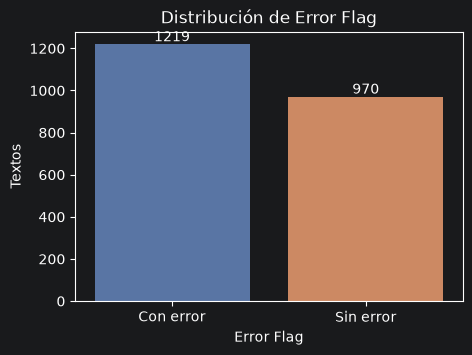

In [66]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=conteo.index, y=conteo.values, ax=ax, palette=["#4C72B0", "#DD8452"], hue=conteo.index, legend=False)
ax.set_title("Distribución de Error Flag")
ax.set_ylabel("Textos")
for i, v in enumerate(conteo.values):
    ax.text(i, v + 15, str(v), ha="center")
plt.show()

## 4. Longitud de los textos

Los modelos tipo BERT aceptan como máximo **512 tokens**. Para saber si los textos caben completos se cuentan los tokens con el tokenizador real de **BiomedBERT** (el modelo propuesto para el detector), ya que un tokenizador de subpalabras puede partir una palabra médica en varios tokens.

In [74]:
from transformers import AutoTokenizer

In [77]:
tokenizer = AutoTokenizer.from_pretrained("microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext")

In [79]:
print("Tokenizador cargado:", type(tokenizer).__name__, "| vocabulario:", tokenizer.vocab_size)

Tokenizador cargado: BertTokenizer | vocabulario: 30522


In [80]:
df["n_palabras"] = df["Text"].str.split().map(len)
# Incluye los tokens especiales [CLS] y [SEP]
df["n_tokens"] = df["Text"].map(lambda t: len(tokenizer(t)["input_ids"]))
df["tokens_por_palabra"] = df["n_tokens"] / df["n_palabras"]

In [81]:
print(df.groupby("Error Flag")[["n_palabras", "n_oraciones", "n_tokens"]].describe().T.round(1))
print("Tokens por palabra:")
print(df["tokens_por_palabra"].describe().round(3))
print(f"Textos con más de 512 tokens: {(df['n_tokens'] > 512).sum()}")

Error Flag             0       1
n_palabras  count  970.0  1219.0
            mean   126.0   125.6
            std     39.7    40.6
            min     31.0    15.0
            25%     97.2    97.0
            50%    123.0   122.0
            75%    152.0   153.0
            max    268.0   267.0
n_oraciones count  970.0  1219.0
            mean    12.7    12.6
            std      6.8     6.9
            min      2.0     2.0
            25%      8.0     8.0
            50%     11.0    11.0
            75%     15.0    15.0
            max     48.0    48.0
n_tokens    count  970.0  1219.0
            mean   173.5   172.8
            std     57.3    58.9
            min     41.0    24.0
            25%    132.2   130.5
            50%    167.0   166.0
            75%    208.8   209.0
            max    411.0   414.0
Tokens por palabra:
count    2189.000
mean        1.374
std         0.097
min         1.133
25%         1.308
50%         1.364
75%         1.429
max         1.923
Name: token

Ejemplo de cómo se parte una oración médica en tokens

In [82]:
oracion = "Her temperature is 38.5 C (101.3 F) and serum potassium is 2.9 mEq/L; hypokalemia is suspected."
print(tokenizer.tokenize(oracion))
print(f"{len(oracion.split())} palabras -> {len(tokenizer.tokenize(oracion))} tokens")

['her', 'temperature', 'is', '38', '.', '5', 'c', '(', '101', '.', '3', 'f', ')', 'and', 'serum', 'potassium', 'is', '2', '.', '9', 'meq', '/', 'l', ';', 'hypo', '##ka', '##le', '##mia', 'is', 'suspected', '.']
16 palabras -> 31 tokens


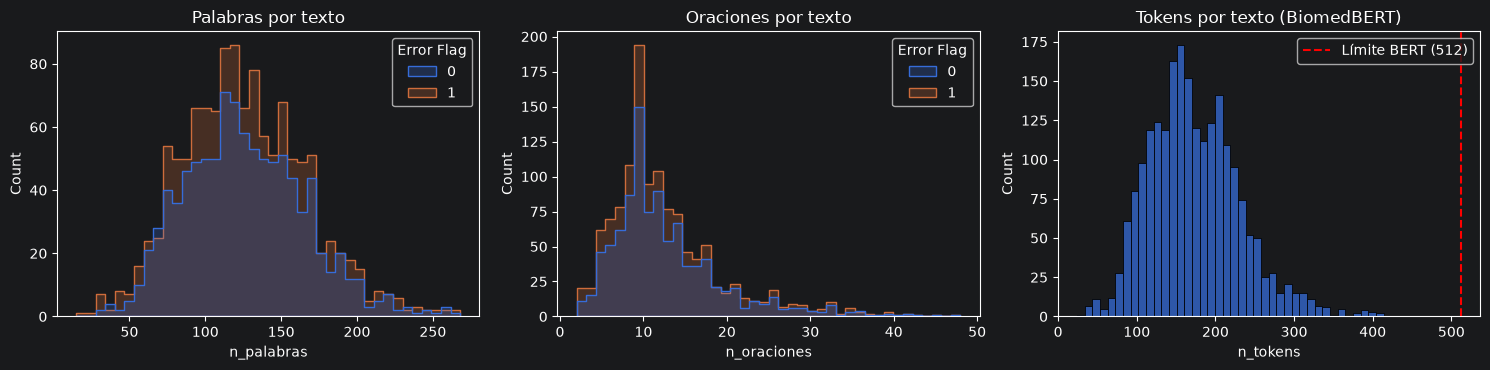

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(data=df, x="n_palabras", hue="Error Flag", bins=40, ax=axes[0], element="step")
axes[0].set_title("Palabras por texto")
sns.histplot(data=df, x="n_oraciones", hue="Error Flag", bins=40, ax=axes[1], element="step")
axes[1].set_title("Oraciones por texto")
sns.histplot(data=df, x="n_tokens", bins=40, ax=axes[2])
axes[2].axvline(512, color="red", linestyle="--", label="Límite BERT (512)")
axes[2].set_title("Tokens por texto (BiomedBERT)")
axes[2].legend()
plt.tight_layout()
plt.show()

## 5. Posición de la oración con error

In [90]:
con_error["pos_relativa"] = con_error["Error Sentence ID"] / (con_error["n_oraciones"] - 1)
# pos_relativa dice en qué parte del texto está el error, en una escala de 0 a 1, para poder comparar textos de distinto largo.

con_error["es_ultima"] = con_error["Error Sentence ID"] == con_error["n_oraciones"] - 1

In [88]:
con_error["pos_relativa"]

0       0.857143
2       1.000000
4       0.500000
6       1.000000
8       1.000000
          ...   
2180    1.000000
2182    0.833333
2184    1.000000
2185    1.000000
2187    1.000000
Name: pos_relativa, Length: 1219, dtype: float64

In [89]:
con_error["es_ultima"]

0       False
2        True
4       False
6        True
8        True
        ...  
2180     True
2182    False
2184     True
2185     True
2187     True
Name: es_ultima, Length: 1219, dtype: bool

In [91]:
print("Posición relativa del error (0 = primera oración, 1 = última):")
print(con_error["pos_relativa"].describe().round(3))
print(f"\nError en la última oración: {con_error['es_ultima'].mean():.2%}")
print(f"Error en la primera oración: {(con_error['Error Sentence ID'] == 0).mean():.2%}")


Posición relativa del error (0 = primera oración, 1 = última):
count    1219.000
mean        0.875
std         0.214
min         0.000
25%         0.818
50%         1.000
75%         1.000
max         1.000
Name: pos_relativa, dtype: float64

Error en la última oración: 62.51%
Error en la primera oración: 1.23%


La media es 0,875: los errores están concentrados al final del texto.

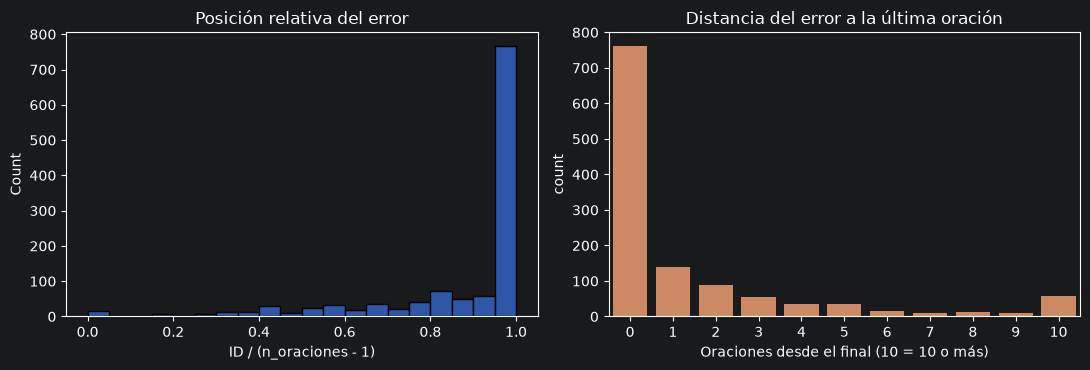

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(con_error["pos_relativa"], bins=20, ax=axes[0])
axes[0].set_title("Posición relativa del error")
axes[0].set_xlabel("ID / (n_oraciones - 1)")
oraciones_desde_final = con_error["n_oraciones"] - 1 - con_error["Error Sentence ID"]
sns.countplot(x=oraciones_desde_final.clip(upper=10), ax=axes[1], color="#DD8452")
axes[1].set_title("Distancia del error a la última oración")
axes[1].set_xlabel("Oraciones desde el final (10 = 10 o más)")
plt.tight_layout()
plt.show()

Esto coincide con el artículo de MEDEC: en el subset MS el error se inyecta "en la mitad o al final" del texto, reemplazando la respuesta de una pregunta de opción múltiple de MedQA.

## 6. Casos clínicos repetidos: pares correcto / con error

Según MEDEC, de cada pregunta de MedQA se generó una versión correcta y una con error. Para comprobarlo se agrupan los textos por su **primera oración** (la presentación del paciente).

In [93]:
df["grupo"] = df["oraciones"].map(lambda s: s[0].strip().lower())

In [95]:
df.head(2)

,Text ID,Text,Sentences,Error Flag,Error Sentence ID,Error Sentence,Corrected Sentence,Corrected Text,oraciones,n_oraciones,n_palabras,n_tokens,tokens_por_palabra,grupo
0,ms-train-0,A 53-year-old man comes to the physician becau...,0 A 53-year-old man comes to the physician bec...,1,6,"After reviewing imaging, the causal pathogen w...","After reviewing imaging, the causal pathogen w...",A 53-year-old man comes to the physician becau...,[A 53-year-old man comes to the physician beca...,8,96,144,1.500000,a 53-year-old man comes to the physician becau...
1,ms-train-1,A 53-year-old man comes to the physician becau...,0 A 53-year-old man comes to the physician bec...,0,-1,NaN,NaN,NaN,[A 53-year-old man comes to the physician beca...,8,90,136,1.511111,a 53-year-old man comes to the physician becau...


In [99]:
tamanos = df.groupby("grupo").size()
print("Grupos (casos clínicos) distintos:", len(tamanos))
print("Tamaño de los grupos:")
print(tamanos.value_counts().sort_index())

Grupos (casos clínicos) distintos: 1240
Tamaño de los grupos:
1    300
2    934
3      3
4      3
Name: count, dtype: int64


In [101]:
composicion = df.groupby("grupo")["Error Flag"].agg(lambda x: tuple(sorted(x))).value_counts()
print("Composición de los grupos (flags):")
print(composicion)

Composición de los grupos (flags):
Error Flag
(0, 1)          934
(1,)            273
(0,)             27
(0, 1, 1)         3
(0, 0, 1, 1)      3
Name: count, dtype: int64


**Implicación:** si se hace un split aleatorio de train/validación, la versión correcta de un caso puede quedar en train y la versión con error en validación (o viceversa), lo que infla las métricas. Hay que usar un **split agrupado** por caso clínico (`GroupShuffleSplit` / `GroupKFold`).

## 7. Naturaleza de la corrección

In [105]:
def diff_spans(erronea, corregida):
    """Devuelve los fragmentos (palabras) que cambian entre la oración errónea y la corregida."""
    a, b = erronea.split(), corregida.split()
    sm = difflib.SequenceMatcher(None, a, b)
    return [
        (" ".join(a[i1:i2]), " ".join(b[j1:j2]))
        for op, i1, i2, j1, j2 in sm.get_opcodes()
        if op != "equal"
    ]

In [108]:
con_error["cambios"] = con_error.apply(lambda r: diff_spans(r["Error Sentence"], r["Corrected Sentence"]), axis=1)
con_error["n_bloques"] = con_error["cambios"].map(len)
con_error["palabras_cambiadas"] = con_error["cambios"].map(lambda c: sum(len(b.split()) for _, b in c))
con_error["similitud"] = con_error.apply(
    lambda r: difflib.SequenceMatcher(None, r["Error Sentence"], r["Corrected Sentence"]).ratio(), axis=1
)

In [112]:
con_error.iloc[0]["Error Sentence"]

'After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae.'

In [113]:
con_error.iloc[0]["Corrected Sentence"]

'After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.'

In [114]:
con_error.iloc[0]["cambios"]

[('Haemophilus influenzae.', 'Streptococcus pneumoniae.')]

In [111]:
con_error.iloc[0][["Error Sentence", "Corrected Sentence", "cambios", "n_bloques", "palabras_cambiadas", "similitud"]]

Error Sentence        After reviewing imaging, the causal pathogen w...
Corrected Sentence    After reviewing imaging, the causal pathogen w...
cambios               [(Haemophilus influenzae., Streptococcus pneum...
n_bloques                                                             1
palabras_cambiadas                                                    2
similitud                                                      0.833333
Name: 0, dtype: object

In [116]:
print("Bloques de cambio por oración:")
print(con_error["n_bloques"].value_counts().sort_index())

Bloques de cambio por oración:
n_bloques
1    1006
2     193
3      17
4       3
Name: count, dtype: int64


In [117]:
print("Palabras nuevas en la corrección:")
print(con_error["palabras_cambiadas"].describe().round(2))

Palabras nuevas en la corrección:
count    1219.00
mean        2.69
std         2.04
min         0.00
25%         1.00
50%         2.00
75%         3.00
max        17.00
Name: palabras_cambiadas, dtype: float64


In [119]:
print("Similitud de caracteres entre oración errónea y corregida:")
print(con_error["similitud"].describe().round(3))

Similitud de caracteres entre oración errónea y corregida:
count    1219.000
mean        0.685
std         0.198
min         0.108
25%         0.561
50%         0.725
75%         0.843
max         0.995
Name: similitud, dtype: float64


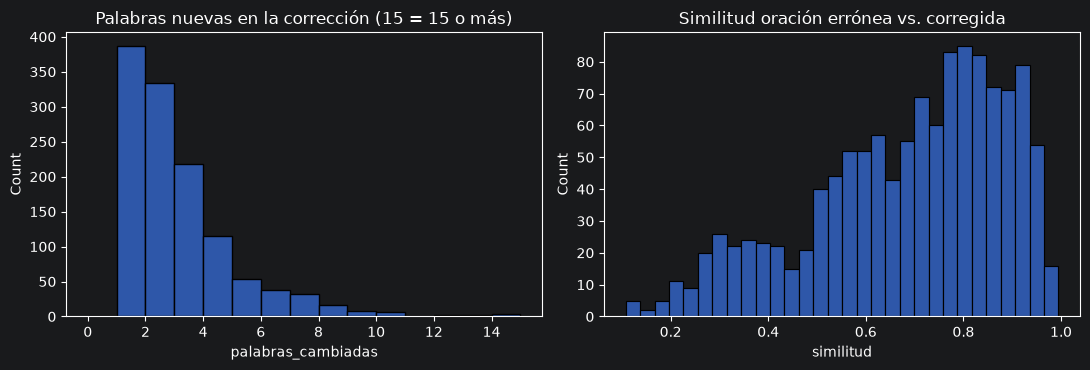

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(con_error["palabras_cambiadas"].clip(upper=15), bins=15, ax=axes[0])
axes[0].set_title("Palabras nuevas en la corrección (15 = 15 o más)")
sns.histplot(con_error["similitud"], bins=30, ax=axes[1])
axes[1].set_title("Similitud oración errónea vs. corregida")
plt.tight_layout()
plt.show()

In [121]:
for cambios in con_error["cambios"].head(15):
    print(" | ".join(f"'{a}' -> '{b}'" for a, b in cambios))

'Haemophilus influenzae.' -> 'Streptococcus pneumoniae.'
'Giardia lamblia.' -> 'Enterobius vermicularis.'
'epidermidis.' -> 'aureus.'
'EBV' -> 'HSV-1'
'Bartonella henselae' -> 'Sporothrix schenckii'
'Nocardia asteroides.' -> 'Actinomyces israelii.'
'streptococcus gallolyticus.' -> 'Streptococcus sanguinis.'
'Rhizopus oryzae' -> 'Clostridium perfringens'
'Neisseria gonorrhoeae' -> 'chlamydia trachomatis'
'Coxiella burneti' -> 'Chlamydophila psittaci'
'Neisseria meningitidis.' -> 'herpes simplex virus.'
'black widow' -> 'brown recluse'
'Neisseria gonorrhoeae.' -> 'chlamydia trachomatis.'
'Histoplasma capsulatum' -> 'Aspergillus fumigatus'
'an aerobic,' -> 'a facultative anaerobic,' | 'chains.' -> 'clusters.'


## 8. Tipo de error aproximado

El CSV no trae la columna de tipo de error. Se aproxima con palabras clave sobre la oración corregida, siguiendo las cinco categorías de MEDEC. Es una heurística, solo sirve para tener una idea de la distribución.

In [122]:
# El orden importa: se asigna la primera regla que coincida
reglas = [
    ("CausalOrganism", r"organism|pathogen|infect|caused by|culture|bacteri|virus|spider"),
    ("Diagnosis", r"diagnos|suspect|consistent with|most likely"),
    ("Pharmacotherapy", r"\b(prescribed|administered|started on|dose|medication|drug|\d+ ?mg)\b(?!/)"),
    ("Management", r"next step|referred|perform|ordered|scheduled|recommended|undergo|testing|discussed"),
    ("Treatment", r"treat|therap|surgery|surgical|repair|resection|initiated"),
]


def error_type(sentence):
    s = sentence.lower()
    for tipo, patron in reglas:
        if re.search(patron, s):
            return tipo
    return "Otro"

In [123]:
con_error["tipo_aprox"] = con_error["Corrected Sentence"].map(error_type)

In [127]:
con_error.head(20).loc[:, ["Corrected Sentence", "tipo_aprox"]]

,Corrected Sentence,tipo_aprox
0,"After reviewing imaging, the causal pathogen w...",CausalOrganism
2,Suspected of infection with Enterobius vermicu...,CausalOrganism
4,Causal organism is Staphylococcus aureus.,CausalOrganism
6,Patient is diagnosed with an HSV-1 infection.,CausalOrganism
8,Sporothrix schenckii was determined as the cau...,CausalOrganism
9,Culture confirms Actinomyces israelii.,CausalOrganism
10,Culture reports indicate the presence of Strep...,CausalOrganism
12,Patient has a Clostridium perfringens infection.,CausalOrganism
13,Further evaluation reveals chlamydia trachomat...,CausalOrganism
14,Chlamydophila psittaci infection is confirmed ...,CausalOrganism


In [128]:
dist_tipos = con_error["tipo_aprox"].value_counts()
print(dist_tipos)

tipo_aprox
Diagnosis          293
Pharmacotherapy    259
Management         247
Otro               242
Treatment           92
CausalOrganism      86
Name: count, dtype: int64


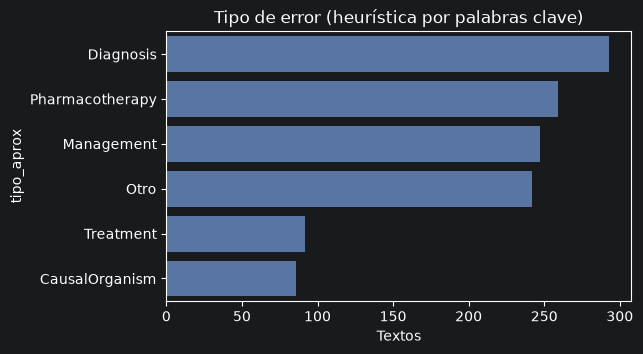

In [129]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=dist_tipos.values, y=dist_tipos.index, ax=ax, color="#4C72B0")
ax.set_title("Tipo de error (heurística por palabras clave)")
ax.set_xlabel("Textos")
plt.show()

In [130]:
for tipo in dist_tipos.index:
    print(f"--- {tipo}")
    for s in con_error[con_error["tipo_aprox"] == tipo]["Corrected Sentence"].head(3):
        print("  ", s)

--- Diagnosis
   Suspected of Streptococcus pneumoniae.
   Patient was diagnosed with meningioma.
   Suspected of normal pressure hydrocephalus.
--- Pharmacotherapy
   An epinephrine autoinjector is prescribed.
   Metoprolol is prescribed.
   All recently administered drugs were discontinued, vital signs were continuously monitored, and intravenous methylprednisolone, ranitidine, and diphenhydramine was administered.
--- Management
   Referred for CBT therapy given concern of adjustment disorder with depressed mood.
   Exam demonstrates a male who appears older than stated age; a CT abdomen with IV contrast is ordered after an abdominal exam is notable for epigastric tenderness to palpation.
   Renal bladder ultrasound is recommended.
--- Otro
   Gram stain reveals a facultative anaerobic, gram-positive cocci in clusters.
   Pathology reports indicate Neisseria species.
   Further evaluation reveals that Moraxella catarrhalis is causing her current condition.
--- Treatment
   Prophylac

## 9. Vocabulario de los fragmentos corregidos

In [133]:
con_error["cambios"].head(5)

0    [(Haemophilus influenzae., Streptococcus pneum...
2       [(Giardia lamblia., Enterobius vermicularis.)]
4                            [(epidermidis., aureus.)]
6                                       [(EBV, HSV-1)]
8        [(Bartonella henselae, Sporothrix schenckii)]
Name: cambios, dtype: object

In [134]:
fragmentos_correctos = Counter(b.strip(".,").lower() for c in con_error["cambios"] for _, b in c if b)
fragmentos_erroneos = Counter(a.strip(".,").lower() for c in con_error["cambios"] for a, _ in c if a)

In [135]:
print("Fragmentos correctos más frecuentes:")
for frag, n in fragmentos_correctos.most_common(15):
    print(f"  {n:3d}  {frag}")

Fragmentos correctos más frecuentes:
   17  performed
   17  started
    8  recommended
    8  scheduled
    8  patient
    7  azithromycin
    7  done
    7  ordered
    6  ceftriaxone
    5  streptococcus pneumoniae
    5  propranolol
    5  prednisone
    4  discontinued
    4  given
    4  prescribed


In [136]:
print("Fragmentos erróneos más frecuentes:")
for frag, n in fragmentos_erroneos.most_common(15):
    print(f"  {n:3d}  {frag}")

Fragmentos erróneos más frecuentes:
   17  patient
   12  performed
    9  ordered
    9  obtained
    8  propranolol
    7  prescribed
    7  mri
    7  administered
    7  required
    7  recommended
    6  metronidazole
    5  done to further evaluate
    4  neisseria meningitidis
    4  doxycycline
    4  ct scan


## 10. Resumen de hallazgos

In [138]:
resumen = {
    "Textos": len(df),
    "Con error (%)": round(df["Error Flag"].mean() * 100, 1),
    "Casos clínicos distintos": df["grupo"].nunique(),
    "Palabras por texto (mediana)": int(df["n_palabras"].median()),
    "Oraciones por texto (mediana)": int(df["n_oraciones"].median()),
    "Tokens por texto (máximo)": int(df["n_tokens"].max()),
    "Tokens por palabra (media)": round(df["tokens_por_palabra"].mean(), 2),
    "Textos > 512 tokens": int((df["n_tokens"] > 512).sum()),
    "Error en la última oración (%)": round(con_error["es_ultima"].mean() * 100, 1),
    "Correcciones de 1 solo bloque (%)": round((con_error["n_bloques"] == 1).mean() * 100, 1),
    "Similitud media errónea vs corregida": round(con_error["similitud"].mean(), 3),
}
pd.Series(resumen, name="valor").to_frame()

,valor
Textos,2189.000
Con error (%),55.700
Casos clínicos distintos,1240.000
Palabras por texto (mediana),122.000
Oraciones por texto (mediana),11.000
Tokens por texto (máximo),414.000
Tokens por palabra (media),1.370
Textos > 512 tokens,0.000
Error en la última oración (%),62.500
Correcciones de 1 solo bloque (%),82.500


## Conclusiones

1. **Tamaño y balance:** 2.189 textos, 55,7% con error. Las clases están casi balanceadas.
2. **Textos cortos:** mediana de 122 palabras, 11 oraciones y 167 tokens. Medido con el tokenizador de BiomedBERT, el promedio es de 1,37 tokens por palabra (números, unidades y términos médicos se parten en varios tokens) y el texto más largo tiene 414 tokens. Todos caben en un encoder tipo BERT (512 tokens) sin truncar.
3. **Segmentación ruidosa:** la columna `Sentences` tiene líneas de continuación sin ID y artefactos como `"Hg."` (801 veces) o `"/dL"` como oraciones aparte. Con el parseo correcto, el `Error Sentence ID` coincide en el 100% de los casos. No hay que re-segmentar: la evaluación usa estos IDs.
4. **Sesgo de posición:** el error está en la última oración en el 62,5% de los casos y la posición relativa media es 0,875. Predecir siempre la última oración es un baseline fuerte.
5. **Casos repetidos:** solo hay 1.240 casos clínicos distintos; 934 aparecen como par (versión correcta + versión con error). Un split aleatorio filtra información entre train y validación, por eso el split debe ser **agrupado por caso clínico**.
6. **Correcciones mínimas:** el 82,5% de las correcciones cambia un solo bloque, con una mediana de 2 palabras nuevas (similitud media de 0,685).
8. **Tipos de error:** según la heurística, predominan Diagnosis, Pharmacotherapy y Management; CausalOrganism y Treatment son minoría. El dataset no trae la etiqueta de tipo, así que el análisis por tipo solo puede ser aproximado.